In [5]:
import numpy as np
import matplotlib.pyplot as plt
import time

# Question 1: Sinusoidal Positional Encoding

In [6]:
def sinusoidal_positional_encoding(seq_len, d_model):
    """Return array with shape (seq_len, d_model)."""
    position = np.arange(seq_len)[:, np.newaxis]
    div_term = np.exp(np.arange(0, d_model, 2) * -(np.log(10000.0) / d_model))
    pe = np.zeros((seq_len, d_model))
    pe[:, 0::2] = np.sin(position * div_term)
    pe[:, 1::2] = np.cos(position * div_term)
    return pe

# Question 2: Scaled Dot-Product Self-Attention

In [7]:
def stable_softmax(x, axis=-1):
    """Numerically stable NumPy softmax."""
    x_max = np.max(x, axis=axis, keepdims=True)
    exp_x = np.exp(x - x_max)
    return exp_x / np.sum(exp_x, axis=axis, keepdims=True)

In [8]:
def scaled_dot_product_attention(Q, K, V, mask=None):
    """
    Q: (..., n_queries, d_k), K: (..., n_keys, d_k), V: (..., n_keys, d_v)
    Return output and attention weights.
    """
    d_k = Q.shape[-1]
    scores = np.matmul(Q, K.swapaxes(-2, -1)) / np.sqrt(d_k)
    
    if mask is not None:
        scores = np.where(mask == 0, -np.inf, scores)
        
    weights = stable_softmax(scores, axis=-1)
    output = np.matmul(weights, V)
    return output, weights

# Question 3: Learnable Projections


In [9]:
def self_attention(X, W_Q, W_K, W_V):
    """Compute Q, K, V projections and attention."""
    Q = np.matmul(X, W_Q)
    K = np.matmul(X, W_K)
    V = np.matmul(X, W_V)
    return scaled_dot_product_attention(Q, K, V)

# Question 4: Causal Self-Attention


In [10]:
def causal_self_attention(Q, K, V):
    """Return causally masked attention output and weights."""
    seq_len = Q.shape[-2]
    # Create an upper triangular mask (1s on and below diagonal, 0s above)
    mask = np.tril(np.ones((seq_len, seq_len)))
    return scaled_dot_product_attention(Q, K, V, mask=mask)

# Question 5: Cross-Attention


In [11]:
def cross_attention(decoder_states, encoder_states, W_Q, W_K, W_V):
    """Return cross-attention outputs and weights."""
    Q = np.matmul(decoder_states, W_Q)
    K = np.matmul(encoder_states, W_K)
    V = np.matmul(encoder_states, W_V)
    return scaled_dot_product_attention(Q, K, V)

# Question 6: Multi-Head Attention


In [12]:
def multi_head_attention(X, W_Q, W_K, W_V, W_O, num_heads, mask=None):
    """Return output (seq_len, d_model) and weights (num_heads, seq_len, seq_len)."""
    seq_len, d_model = X.shape
    d_k = d_model // num_heads
    
    Q = np.matmul(X, W_Q).reshape(seq_len, num_heads, d_k).swapaxes(0, 1)
    K = np.matmul(X, W_K).reshape(seq_len, num_heads, d_k).swapaxes(0, 1)
    V = np.matmul(X, W_V).reshape(seq_len, num_heads, d_k).swapaxes(0, 1)
    
    head_outputs, weights = scaled_dot_product_attention(Q, K, V, mask=mask)
    
    # Concatenate heads
    concat_out = head_outputs.swapaxes(0, 1).reshape(seq_len, d_model)
    output = np.matmul(concat_out, W_O)
    
    return output, weights

# Question 8: Transformer Encoder Block


In [13]:
def layer_norm(X, gamma, beta, eps=1e-5):
    mean = np.mean(X, axis=-1, keepdims=True)
    var = np.var(X, axis=-1, keepdims=True)
    X_norm = (X - mean) / np.sqrt(var + eps)
    return gamma * X_norm + beta

In [14]:
def feed_forward(X, W1, b1, W2, b2):
    hidden = np.maximum(0, np.matmul(X, W1) + b1) # ReLU
    return np.matmul(hidden, W2) + b2

In [15]:
def transformer_encoder_block(X, params):
    """Return (seq_len, d_model) output."""
    # MHA
    mha_out, _ = multi_head_attention(
        X, params['W_Q'], params['W_K'], params['W_V'], params['W_O'], params['num_heads']
    )
    # Add & Norm
    H = layer_norm(X + mha_out, params['gamma1'], params['beta1'])
    # FFN
    ffn_out = feed_forward(H, params['W1'], params['b1'], params['W2'], params['b2'])
    # Add & Norm
    Y = layer_norm(H + ffn_out, params['gamma2'], params['beta2'])
    return Y


# Question 9: Transformer Decoder Block


In [16]:
def transformer_decoder_block(decoder_input, encoder_output, params):
    """Return decoder output after masked attention, cross-attention and FFN."""
    seq_len = decoder_input.shape[0]
    causal_mask = np.tril(np.ones((seq_len, seq_len)))
    
    # 1. Masked Self-Attention
    mha_self, _ = multi_head_attention(
        decoder_input, params['W_Q_self'], params['W_K_self'], params['W_V_self'], params['W_O_self'], 
        params['num_heads'], mask=causal_mask
    )
    norm1 = layer_norm(decoder_input + mha_self, params['gamma1'], params['beta1'])
    
    # 2. Cross-Attention
    # Reusing scaled_dot_product structure inside a manual multi-head wrapper for cross attention
    d_model = decoder_input.shape[-1]
    d_k = d_model // params['num_heads']
    
    Q_cross = np.matmul(norm1, params['W_Q_cross']).reshape(-1, params['num_heads'], d_k).swapaxes(0, 1)
    K_cross = np.matmul(encoder_output, params['W_K_cross']).reshape(-1, params['num_heads'], d_k).swapaxes(0, 1)
    V_cross = np.matmul(encoder_output, params['W_V_cross']).reshape(-1, params['num_heads'], d_k).swapaxes(0, 1)
    
    cross_out_heads, _ = scaled_dot_product_attention(Q_cross, K_cross, V_cross)
    cross_concat = cross_out_heads.swapaxes(0, 1).reshape(-1, d_model)
    mha_cross = np.matmul(cross_concat, params['W_O_cross'])
    
    norm2 = layer_norm(norm1 + mha_cross, params['gamma2'], params['beta2'])
    
    # 3. Feed Forward
    ffn_out = feed_forward(norm2, params['W1'], params['b1'], params['W2'], params['b2'])
    out = layer_norm(norm2 + ffn_out, params['gamma3'], params['beta3'])
    
    return out


# Question 10: Benchmark Attention

In [17]:
def benchmark_attention(seq_lengths, d_model, num_heads):
    """Report timing and attention-matrix memory."""
    times = []
    memories = []
    
    for n in seq_lengths:
        Q = np.random.randn(num_heads, n, d_model // num_heads)
        K = np.random.randn(num_heads, n, d_model // num_heads)
        V = np.random.randn(num_heads, n, d_model // num_heads)
        
        start_time = time.time()
        for _ in range(100): # run multiple times for stable average
            _ = scaled_dot_product_attention(Q, K, V)
        end_time = time.time()
        
        times.append((end_time - start_time) / 100)
        
        # Memory in bytes (float64 = 8 bytes). Matrix is (num_heads, n, n)
        memory_bytes = num_heads * n * n * 8
        memories.append(memory_bytes)
        
        print(f"Seq Len: {n} | Time: {times[-1]*1000:.4f} ms | Memory: {memory_bytes / 1024:.2f} KB")
        
    plt.figure(figsize=(8,4))
    plt.plot(seq_lengths, times, marker='o')
    plt.title("Attention Computation Time vs Sequence Length")
    plt.xlabel("Sequence Length")
    plt.ylabel("Time (seconds)")
    plt.grid(True)
    plt.show()


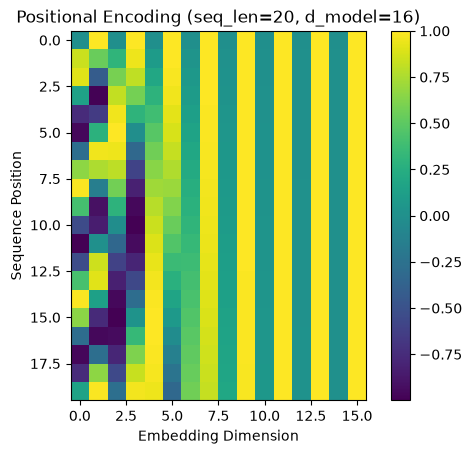

Seq Len: 32 | Time: 0.0263 ms | Memory: 32.00 KB
Seq Len: 64 | Time: 0.0745 ms | Memory: 128.00 KB
Seq Len: 128 | Time: 0.2115 ms | Memory: 512.00 KB
Seq Len: 256 | Time: 0.7315 ms | Memory: 2048.00 KB
Seq Len: 512 | Time: 2.9102 ms | Memory: 8192.00 KB


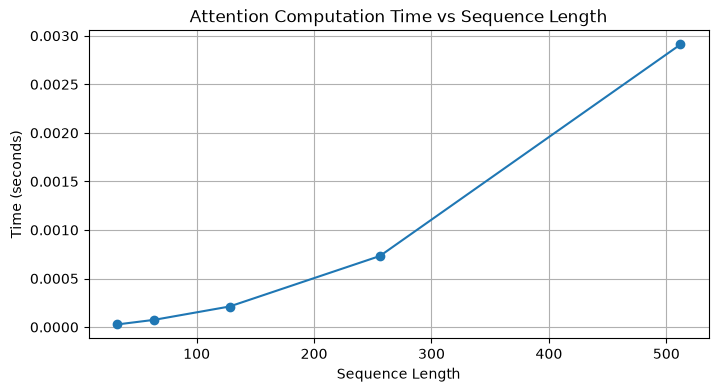

In [ ]:
if __name__ == "__main__":
    # Q1 Visualization
    pe = sinusoidal_positional_encoding(20, 16)
    plt.imshow(pe, cmap='viridis')
    plt.title("Positional Encoding (seq_len=20, d_model=16)")
    plt.xlabel("Embedding Dimension")
    plt.ylabel("Sequence Position")
    plt.colorbar()
    plt.show()

    # Q10 Benchmark
    seq_lengths = [32, 64, 128, 256, 512]
    benchmark_attention(seq_lengths, d_model=64, num_heads=4)